# Small-noise SDE

Reuses the model and instanton code from `compute.py`.

We consider the two-dimensional stochastic differential equation
$$
\begin{aligned}
dX_{1,t}^{\varepsilon}
&=\left(-X_{1,t}^{\varepsilon}
-X_{1,t}^{\varepsilon}X_{2,t}^{\varepsilon}\right),dt
+\sqrt{\varepsilon} dW_{1,t},\\
dX_{2,t}^{\varepsilon}
&=\left(-4X_{2,t}^{\varepsilon}
+(X_{1,t}^{\varepsilon})^2\right),dt
+\frac{\sqrt{\varepsilon}}{2} dW_{2,t},
\end{aligned}
$$
with initial condition $X_0^\varepsilon=(0,0)$, terminal time $T=1$, and independent standard Brownian motions $W_1$ and $W_2$. The parameter $\varepsilon>0$ controls the noise strength.

Our objective is to estimate the terminal exceedance probability
$$
P_\varepsilon
=\mathbb{P}\left(f(X_T^\varepsilon)\ge z\right),
\qquad
f(x)=x_1+2x_2,\qquad z=3.
$$
As $\varepsilon$ decreases, this event becomes increasingly rare, making direct Monte Carlo estimation difficult.

We compare six sampling methods: direct Monte Carlo, vanilla IBIS, IBIS with a control variate, subspace cross-entropy (CE), pecan IBIS, and pecan IBIS with a control variate. 

This notebook provides a single-run reproduction of the comparison in Figure 1.1 of the accompanying paper. It uses the same SDE, event threshold, time discretization, noise levels, and sample budgets. The SDE is simulated using an integrating-factor scheme with 2000 time steps, at 16 logarithmically spaced values of $\varepsilon$ between $0.01$ and $10$.

Each method uses a total budget of 100,000 simulated paths per noise level. For subspace CE, this budget is split into 50,000 training paths and 50,000 independent evaluation paths. The paper reports the median estimated CoV over 20 independent repetitions for subspace CE; this notebook performs only one training-and-evaluation run at each noise level Consequently, the CE curve may fluctuate more than the curve in the paper. Fixed random seeds make the experiment repeatable.

For each method and noise level, we estimate the event probability and quantify its relative sampling uncertainty using the estimated coefficient of variation (CoV), defined as the estimated standard error divided by the probability estimate:
$$
\widehat{\operatorname{CoV}}(\widehat P_\varepsilon) = \frac{\widehat{\operatorname{SE}}(\widehat P_\varepsilon)}
{\widehat P_\varepsilon}.
$$
We plot this quantity against the noise strength to reproduce the comparison in Figure 1.1, and report selected probability estimates corresponding to those in the figure caption. At noise levels where direct Monte Carlo produces no event hits, its estimated CoV is undefined, so these points are omitted.


In [1]:
import numpy as np
from compute import nt, dt, dim, z, getB, getIF, getSigma, getA, getF, getTimeIntegral, Instanton, SecondVariationOperator

## Instanton (computed once, eps-independent)

`theta_z` is compute.py's control variable; the SDE forcing is `A(theta_z) = sigma^2 theta_z`, and the standard (Id-weighted) instanton noise direction is `eta_z = sigma * theta_z`. The rate function is $I_F(z) = \frac{1}{2}\|\eta_z\|^2_{L^2([0,T])}$.

In [2]:
import contextlib, io

instanton = Instanton()
with contextlib.redirect_stdout(io.StringIO()):  # silence the solver's internal progress prints
    obsValue, action, lbda_z, theta_z, phi_z, dS = instanton.searchInstantonViaAugmented(z)

print(f'instanton check: f(phi_z(T)) = {obsValue:.6f}  (target z = {z})')
print(f'rate function I_F(z) = {action:.6f}')
print(f'lambda_z = {lbda_z:.6f}')

instanton check: f(phi_z(T)) = 3.000000  (target z = 3.0)
rate function I_F(z) = 4.614597
lambda_z = 2.670710


In [3]:
eta_z = getSigma(theta_z.T).T  # eta_z(t) = sigma * theta_z(t)

check = 0.5 * getTimeIntegral(eta_z, eta_z)
print(f'0.5*||eta_z||^2_(L2,dt) = {check:.6f}  (should equal I_F(z) = {action:.6f})')

0.5*||eta_z||^2_(L2,dt) = 4.614597  (should equal I_F(z) = 4.614597)


## Direct Monte Carlo

Fixed sample budget `M` (not grow-until-hit), so it can report 0 hits / "impossible" once eps gets small, matching the note's discussion of direct MC breaking down.

In [4]:
def direct_mc(eps, M, nBatch, rng):
    """Fixed-budget direct Monte Carlo estimate of P[f(X_T^eps) >= z]."""
    hits = 0
    for _ in range(M // nBatch):
        X = np.zeros((dim, nBatch))
        for i in range(nt):
            X = getIF(X + dt * getB(X) + np.sqrt(eps * dt) * getSigma(rng.standard_normal((dim, nBatch))), dt)
        hits += np.sum(getF(X) >= z)
    prob = hits / M
    std = np.sqrt(prob * (1. - prob) / M)
    return prob, std, M * nt  # nEvals = one forward pass per sample

## Implementation of Various Methods

The following cells implement multiple variants of Ibis.

`vanilla_ibis` is the plain Ibis, only shifting the distribution mean to the LDT optimizer $\eta_z$.

`vanilla_ibis_cv` is Ibis coupled with control variate.

`ce_train` fits a full Gaussian in the instanton/curvature subspace using IBIS training paths. `ce_test` evaluates a fixed fit using fresh paths. `subspace_ce` combines the two stages. The fitted mean and covariance describe dimensionless fluctuations around the instanton. The older reuse functions are retained below but excluded from the comparison sweep.

`pecan_ibis` adjusts the sampling distribution along the instanton direction and rescales fluctuations in the perpendicular directions using local curvature information.

`pecan_ibis_cv` adds a control variate based on the quadratic approximation of the rare-event boundary to reduce sampling variance.


In [5]:
def vanilla_ibis(eps, M, nBatch, rng):
    """Fixed-budget vanilla IBIS estimate of P[f(X_T^eps) >= z]."""
    prefac = np.sqrt(eps / (2. * np.pi)) * np.exp(-action / eps)
    samples = []
    for _ in range(M // nBatch):
        X = np.zeros((dim, nBatch))
        S = np.zeros(nBatch)
        for i in range(nt):
            rstep = rng.standard_normal((dim, nBatch))
            S += np.sqrt(dt) * np.sum(eta_z[i][:, None] * rstep, axis=0)
            X = getIF(X + dt * (getB(X) + getA(theta_z[i])[:, None]) + np.sqrt(eps * dt) * getSigma(rstep), dt)
        indicator = (getF(X) >= z).astype(float)
        with np.errstate(over='ignore'):
            samples.append(np.sqrt(2. * np.pi / eps) * indicator * np.exp(-S / np.sqrt(eps)))
    samples = np.concatenate(samples)
    res = samples.mean()
    std = samples.std(ddof=1) / np.sqrt(M)
    return res * prefac, std * prefac, M * nt

In [6]:
# IBIS+CV: SORM control variate via dominant eigenpairs of the projected second-variation operator
from scipy.sparse.linalg import eigs

with contextlib.redirect_stdout(io.StringIO()):
    A_op = SecondVariationOperator(phi_z, theta_z, lbda_z)
    evals, evecs = eigs(A_op, k=200, which='LM', tol=1e-8)
evals = evals.real
evecs = evecs.real / np.sqrt(np.sum(evecs.real**2 * dt, axis=0))[None, :]  # normalize each eigenvector to unit L2,dt norm
evecs_mat = evecs.reshape(nt + 1, dim, evals.shape[0])[:nt].reshape(nt * dim, evals.shape[0])  # (nt*dim, K)

cf_sorm = float((1. / np.sqrt(2. * action * np.prod(1. - evals))).real)  # analytic SORM prefactor = E[Y] for the CV
print(f'SORM prefactor cf = {cf_sorm:.6f}  (max |eigenvalue| = {np.max(np.abs(evals)):.4f})')
print(f'one-time eigendecomposition cost: {A_op.counter} matvecs (fwd+bwd solve each) ~= {A_op.counter * 2 * nt:.2e} evals, shared by Ibis+CV and CE')

SORM prefactor cf = 0.322824  (max |eigenvalue| = 0.1628)
one-time eigendecomposition cost: 402 matvecs (fwd+bwd solve each) ~= 1.61e+06 evals, shared by Ibis+CV and CE


In [7]:
# Y = quadratic (SORM) approximation of the IBIS integrand X, built from the same noise draws -> control variate
def vanilla_ibis_cv(eps, M, nBatch, rng):
    """Fixed-budget IBIS+CV estimate of P[f(X_T^eps) >= z], using the SORM quadratic approx as control variate."""
    prefac = np.sqrt(eps / (2. * np.pi)) * np.exp(-action / eps)
    Xs, Ys = [], []
    for _ in range(M // nBatch):
        R = rng.standard_normal((nt, dim, nBatch))
        X = np.zeros((dim, nBatch))
        for i in range(nt):
            X = getIF(X + dt * (getB(X) + getA(theta_z[i])[:, None]) + np.sqrt(eps * dt) * getSigma(R[i]), dt)
        R_mat = R.reshape(nt * dim, nBatch)
        S = np.sqrt(dt) * (eta_z[:nt].reshape(1, nt * dim) @ R_mat).ravel()
        Cproj = np.sqrt(dt) * (evecs_mat.T @ R_mat)              # projection of the noise onto each eigenvector
        QF = np.sum(evals[:, None] * Cproj**2, axis=0)           # quadratic form sum_i mu_i * c_i^2
        Q = S / np.sqrt(eps) + 0.5 * QF                           # SORM approx of (F(phys)-z)/eps >= 0
        indicatorX = (getF(X) >= z).astype(float)
        indicatorY = (Q >= 0).astype(float)
        with np.errstate(over='ignore'):
            Xs.append(np.sqrt(2. * np.pi / eps) * indicatorX * np.exp(-S / np.sqrt(eps)))
            Ys.append(np.sqrt(2. * np.pi / eps) * indicatorY * np.exp(-S / np.sqrt(eps) + S**2 / (4. * action)))
    X_, Y_ = np.concatenate(Xs), np.concatenate(Ys)
    varX, varY = X_.var(ddof=1), Y_.var(ddof=1)
    covXY = np.cov(X_, Y_, ddof=1)[0, 1]
    cstar = -covXY / varY
    resCV = X_.mean() + cstar * (Y_.mean() - cf_sorm)
    stdCV = np.sqrt((1. - covXY**2 / (varX * varY)) * varX / M)
    return resCV * prefac, stdCV * prefac, M * nt  # marginal cost; eigendecomposition is a shared one-time cost

In [8]:
# CE: subspace = e_z + dominant curvature eigenvectors (|mu_i| > 1e-2); fit a full Gaussian here
ce_idx = np.where(np.abs(evals) > 1e-2)[0]
ez_continuous = (eta_z[:nt] / np.sqrt(2. * action)).reshape(nt * dim)         # e_z normalized to unit L2,dt norm
dirs_mat = np.concatenate([ez_continuous[:, None], evecs_mat[:, ce_idx]], axis=1)  # (nt*dim, K_sub)
K_sub = dirs_mat.shape[1]
print(f'CE subspace dimension = {K_sub} (e_z + {len(ce_idx)} dominant eigenvectors)')

CE subspace dimension = 8 (e_z + 7 dominant eigenvectors)


In [9]:
# Fit a full Gaussian to standardized fluctuations around the IBIS instanton.
# These mean/cov parameters are dimensionless, not physical-noise coordinates.
def _ce_check_inputs(eps, nSamples, nBatch):
    if not np.isfinite(eps) or eps <= 0:
        raise ValueError("eps must be positive and finite.")
    for name, value, minimum in [("nSamples", nSamples, 2), ("nBatch", nBatch, 1)]:
        if not isinstance(value, (int, np.integer)) or value < minimum:
            raise ValueError(f"{name} must be an integer >= {minimum}.")
    if dirs_mat.shape != (nt * dim, K_sub):
        raise ValueError("The CE basis has the wrong shape; rerun its setup cell.")
    if not np.allclose(dt * dirs_mat.T @ dirs_mat, np.eye(K_sub), atol=1e-8, rtol=1e-8):
        raise ValueError("The CE basis must be orthonormal in the dt-weighted inner product.")


def ce_train(eps, N_train, nBatch, rng):
    """One CE fit from N_train IBIS paths; return dimensionless mean and covariance."""
    _ce_check_inputs(eps, N_train, nBatch)
    coordinates = np.empty((K_sub, N_train))
    log_weights = np.full(N_train, -np.inf)
    eta_flat = eta_z[:nt].reshape(nt * dim)

    for start in range(0, N_train, nBatch):
        batch = min(nBatch, N_train - start)
        R = rng.standard_normal((nt, dim, batch))
        R_mat = R.reshape(nt * dim, batch)
        X = np.zeros((dim, batch))
        for i in range(nt):
            X = getIF(
                X + dt * (getB(X) + getA(theta_z[i])[:, None])
                + np.sqrt(eps * dt) * getSigma(R[i]), dt
            )
        if not np.all(np.isfinite(X)):
            raise FloatingPointError("Non-finite SDE state during CE training.")
        coordinates[:, start:start + batch] = np.sqrt(dt) * (dirs_mat.T @ R_mat)
        S = np.sqrt(dt) * (eta_flat @ R_mat)
        # The omitted -I/eps is constant and cancels in normalized training weights.
        log_weights[start:start + batch] = np.where(getF(X) >= z, -S / np.sqrt(eps), -np.inf)

    shift = np.max(log_weights)
    if not np.isfinite(shift):
        raise ValueError("No finite event weights in CE training.")
    weights = np.exp(log_weights - shift)
    weights /= weights.sum()  # Normalize over all training batches together.
    mean = coordinates @ weights
    centered = coordinates - mean[:, None]
    cov = (centered * weights[None, :]) @ centered.T
    cov = 0.5 * (cov + cov.T)
    if not np.all(np.isfinite(cov)) or np.linalg.eigvalsh(cov).min() <= 0:
        raise ValueError("CE covariance is not positive definite; inspect or increase training samples.")
    return mean, cov


In [10]:
def ce_test(eps, M, nBatch, rng, mean, cov):
    """Test a fixed CE fit on M fresh paths; return probability, standard error, cost.

    mean and cov parameterize standardized noise fluctuations around eta_z.
    Use a fresh random stream, or the generator after training, for independent tests.
    """
    _ce_check_inputs(eps, M, nBatch)
    mean, cov = np.asarray(mean, dtype=float), np.asarray(cov, dtype=float)
    if mean.shape != (K_sub,) or cov.shape != (K_sub, K_sub):
        raise ValueError("mean/cov dimensions must match the CE subspace.")
    if not np.all(np.isfinite(mean)) or not np.all(np.isfinite(cov)):
        raise ValueError("mean and cov must be finite.")
    if not np.allclose(cov, cov.T, atol=1e-12, rtol=1e-10):
        raise ValueError("cov must be symmetric.")
    cov = 0.5 * (cov + cov.T)
    try:
        L = np.linalg.cholesky(cov)
    except np.linalg.LinAlgError as error:
        raise ValueError("cov must be positive definite.") from error
    logdet_cov = 2.0 * np.log(np.diag(L)).sum()
    eta_flat = eta_z[:nt].reshape(nt * dim)
    discrete_action = 0.5 * dt * np.dot(eta_flat, eta_flat)
    log_samples = np.full(M, -np.inf)

    for start in range(0, M, nBatch):
        batch = min(nBatch, M - start)
        R = rng.standard_normal((nt, dim, batch))
        R_mat = R.reshape(nt * dim, batch)
        a = np.sqrt(dt) * (dirs_mat.T @ R_mat)
        # a is standard Gaussian and independent of the orthogonal complement.
        c = mean[:, None] + L @ a
        R_mat += np.sqrt(dt) * (dirs_mat @ (c - a))
        X = np.zeros((dim, batch))
        for i in range(nt):
            X = getIF(
                X + dt * (getB(X) + getA(theta_z[i])[:, None])
                + np.sqrt(eps * dt) * getSigma(R[i]), dt
            )
        if not np.all(np.isfinite(X)):
            raise FloatingPointError("Non-finite SDE state during CE testing.")
        S = np.sqrt(dt) * (eta_flat @ R_mat)
        whitened = np.linalg.solve(L, c - mean[:, None])
        logratio = (
            -0.5 * np.sum(c**2, axis=0)
            + 0.5 * np.sum(whitened**2, axis=0)
            + 0.5 * logdet_cov
        )
        log_samples[start:start + batch] = np.where(
            getF(X) >= z,
            -discrete_action / eps - S / np.sqrt(eps) + logratio,
            -np.inf
        )

    shift = np.max(log_samples)
    if not np.isfinite(shift):
        raise ValueError("No finite event contributions in CE testing.")
    # Scaling before computing variance avoids squaring probabilities near 1e-203.
    scaled = np.exp(log_samples - shift)
    scaled_mean = scaled.mean()
    scaled_se = scaled.std(ddof=1) / np.sqrt(M)
    prob = np.exp(shift + np.log(scaled_mean))
    std = np.exp(shift + np.log(scaled_se)) if scaled_se > 0 else 0.0
    if not np.isfinite(prob) or not np.isfinite(std) or prob == 0:
        raise FloatingPointError("CE probability or standard error is outside floating-point range.")
    return prob, std, M * nt


def subspace_ce(eps, M, N_train, nBatch, rng):
    """One training fit followed by independent testing; preserve the original API."""
    mean, cov = ce_train(eps, N_train, nBatch, rng)
    prob, std, test_cost = ce_test(eps, M, nBatch, rng, mean, cov)
    return prob, std, N_train * nt + test_cost


In [11]:
def pecan_ibis(eps, M, nBatch, rng, sigma2=1.0):
    """Pecan-IBIS estimate of P[f(X_T^eps) >= z].
 
    Tailored mixture in the instanton direction + curvature-undoing
    G^{-1/2} transform in the perpendicular directions.
    """
    prefac = np.sqrt(eps / (2. * np.pi)) * np.exp(-action / eps) * cf_sorm  # = sqrt(eps/2pi) e^{-I/eps} [2I det(1-lam pr H pr)]^{-1/2}
    Gsqrt = np.sqrt(1. - evals)                       # sqrt(1 - mu_i)
    norm_const = 1. + np.sqrt(np.pi * eps * sigma2 / 2.)   # [1 + sqrt(pi eps sigma^2 / 2)]
    p_exp = 1. / norm_const                            # prob. of the exponential (upper) branch
    r = np.sqrt(2. * action)                           # ||eta_z||
 
    samples = []
    for _ in range(M // nBatch):
        R0 = rng.standard_normal((nt, dim, nBatch))
        R0_mat = R0.reshape(nt * dim, nBatch)
 
        # eta^perp: standard noise with the e_z component removed
        a_ez0 = np.sqrt(dt) * (ez_continuous @ R0_mat)                  # e_z coordinate of R0
        Rperp = R0_mat - np.sqrt(dt) * np.outer(ez_continuous, a_ez0)
 
        # curvature-eigenvector coordinates of eta^perp, and the offset
        c = np.sqrt(dt) * (evecs_mat.T @ Rperp)                          # (K, nBatch)
        QF_G = np.sum(evals[:, None] * c**2 / (1. - evals)[:, None], axis=0)  # <G^{-1/2}eta, lam H G^{-1/2}eta>
        thr = -0.5 * QF_G                                                # offset = -lambda/2 <..>
 
        # sample s ~ rho_||( . | G^{-1/2} eta^perp)
        u = rng.random(nBatch)
        s = np.where(u < p_exp,
                     thr + rng.standard_exponential(nBatch),            # exponential tail, s >= thr
                     thr - np.abs(rng.standard_normal(nBatch)) * np.sqrt(eps * sigma2))  # half-Gaussian, s < thr
 
        # build the physical noise:  delta_eta = sqrt(eps) s e_z/||eta_z|| + G^{-1/2} eta^perp
        c_scaled = c / Gsqrt[:, None]                                    # scale eigen-coords by 1/sqrt(1-mu_i)
        R_mat = Rperp + np.sqrt(dt) * (evecs_mat @ (c_scaled - c))       # G^{-1/2} eta^perp
        a_ez = np.sqrt(eps) * s / r                                      # e_z coordinate for the parallel piece
        R_mat = R_mat + np.sqrt(dt) * np.outer(ez_continuous, a_ez)
        R = R_mat.reshape(nt, dim, nBatch)
 
        # true indicator: run the SDE with the constructed noise (instanton forcing + fluctuation)
        X = np.zeros((dim, nBatch))
        for i in range(nt):
            X = getIF(X + dt * (getB(X) + getA(theta_z[i])[:, None]) + np.sqrt(eps * dt) * getSigma(R[i]), dt)
        indicator = (getF(X) >= z).astype(float)
 
        # J^eps
        with np.errstate(over='ignore'):
            base = norm_const * indicator * np.exp(-eps * s**2 / (4. * action))   # e^{-eps s^2 / (2 ||eta_z||^2)}
            lower = np.exp(-s + thr) * np.exp((s - thr)**2 / (2. * eps))          # s < thr branch
            branch = np.where(s >= thr, 1.0, lower)                               # s >= thr branch is 1
            samples.append(base * branch)
 
    samples = np.concatenate(samples)
    res = samples.mean()
    std = samples.std(ddof=1) / np.sqrt(M)
    return res * prefac, std * prefac, M * nt

In [12]:
def pecan_ibis_cv(eps, M, nBatch, rng, sigma2=1.0):
    """Pecan-IBIS with the paraboloid control variate K (E[K] = 1)."""
    prefac = np.sqrt(eps / (2. * np.pi)) * np.exp(-action / eps) * cf_sorm
    Gsqrt = np.sqrt(1. - evals)
    norm_const = 1. + np.sqrt(np.pi * eps * sigma2 / 2.)
    p_exp = 1. / norm_const
    r = np.sqrt(2. * action)
 
    Xs, Ys = [], []
    for _ in range(M // nBatch):
        R0 = rng.standard_normal((nt, dim, nBatch))
        R0_mat = R0.reshape(nt * dim, nBatch)
 
        a_ez0 = np.sqrt(dt) * (ez_continuous @ R0_mat)
        Rperp = R0_mat - np.sqrt(dt) * np.outer(ez_continuous, a_ez0)
 
        c = np.sqrt(dt) * (evecs_mat.T @ Rperp)
        QF_G = np.sum(evals[:, None] * c**2 / (1. - evals)[:, None], axis=0)
        thr = -0.5 * QF_G
 
        u = rng.random(nBatch)
        s = np.where(u < p_exp,
                     thr + rng.standard_exponential(nBatch),
                     thr - np.abs(rng.standard_normal(nBatch)) * np.sqrt(eps * sigma2))
 
        c_scaled = c / Gsqrt[:, None]
        R_mat = Rperp + np.sqrt(dt) * (evecs_mat @ (c_scaled - c))
        a_ez = np.sqrt(eps) * s / r
        R_mat = R_mat + np.sqrt(dt) * np.outer(ez_continuous, a_ez)
        R = R_mat.reshape(nt, dim, nBatch)
 
        X = np.zeros((dim, nBatch))
        for i in range(nt):
            X = getIF(X + dt * (getB(X) + getA(theta_z[i])[:, None]) + np.sqrt(eps * dt) * getSigma(R[i]), dt)
        indicator = (getF(X) >= z).astype(float)
 
        with np.errstate(over='ignore'):
            base = norm_const * indicator * np.exp(-eps * s**2 / (4. * action))
            lower = np.exp(-s + thr) * np.exp((s - thr)**2 / (2. * eps))
            J = base * np.where(s >= thr, 1.0, lower)
            Jtilde = norm_const * (s >= thr).astype(float)      # paraboloid CV, exact E = 1
        Xs.append(J)
        Ys.append(Jtilde)
 
    X_, Y_ = np.concatenate(Xs), np.concatenate(Ys)
    varX, varY = X_.var(ddof=1), Y_.var(ddof=1)
    covXY = np.cov(X_, Y_, ddof=1)[0, 1]
    cstar = -covXY / varY
    resCV = X_.mean() + cstar * (Y_.mean() - 1.0)
    stdCV = np.sqrt((1. - covXY**2 / (varX * varY)) * varX / M)
    return resCV * prefac, stdCV * prefac, M * nt
 

## Sweep over eps and compare


In [13]:
eps_list = np.logspace(-2, 1, 16)
M = 20_000
N_train = 10_000
M_CE = 10_000
nBatch = 2_000

# uncomment these if run with 100k samples
# M = 100_000
# N_train = 50_000
# M_CE = 50_000
# nBatch = 10_000

rng = np.random.default_rng(42)

# Keys match the existing plotting and CSV column names.
methods = [
    ("MC",    "MC",          direct_mc,        (M,)),
    ("Ibis",  "IBIS",        vanilla_ibis,     (M,)),
    ("CV",    "IBIS+CV",     vanilla_ibis_cv,  (M,)),
    ("CE",    "CE",          subspace_ce,      (M_CE, N_train)),
    ("Pecan",   "Pecan IBIS",    pecan_ibis,    (M,)),
    ("PecanCV", "Pecan IBIS+CV", pecan_ibis_cv, (M,)),
]

results = {"eps": []}
for key, _, _, _ in methods:
    results[f"prob{key}"] = []
    results[f"cov{key}"] = []

header = f"{'eps':>6}" + "".join(f" | {key:>9} {'CoV':>7}"for key, _, _, _ in methods)
print(header)
print("-" * len(header))

for eps in eps_list:
    row = {}

    for key, _, sampler, args in methods:
        prob, std, _ = sampler(eps, *args, nBatch, rng)
        cov = std / prob if prob > 0 else np.nan
        row[key] = (prob, cov)

    results["eps"].append(eps)
    for key, _, _, _ in methods:
        prob, cov = row[key]
        results[f"prob{key}"].append(prob)
        results[f"cov{key}"].append(cov)

    print(
        f"{eps:6.3f}" + "".join(
            f" | {row[key][0]:9.2e} {row[key][1]:7.1e}"
            for key, _, _, _ in methods
        )
    )

   eps |        MC     CoV |      Ibis     CoV |        CV     CoV |        CE     CoV |     Pecan     CoV |   PecanCV     CoV
------------------------------------------------------------------------------------------------------------------------------
 0.010 |  0.00e+00     nan | 5.04e-203 1.9e-02 | 5.01e-203 1.1e-03 | 4.94e-203 4.3e-03 | 5.01e-203 1.1e-03 | 5.01e-203 1.8e-04
 0.016 |  0.00e+00     nan | 5.70e-129 1.7e-02 | 5.76e-129 1.9e-03 | 5.73e-129 4.9e-03 | 5.76e-129 1.2e-03 | 5.75e-129 2.0e-04
 0.025 |  0.00e+00     nan |  3.27e-82 1.5e-02 |  3.34e-82 1.5e-03 |  3.33e-82 4.4e-03 |  3.34e-82 1.4e-03 |  3.35e-82 2.3e-04
 0.040 |  0.00e+00     nan |  1.18e-52 1.4e-02 |  1.17e-52 1.4e-03 |  1.18e-52 6.9e-03 |  1.17e-52 1.6e-03 |  1.17e-52 2.7e-04
 0.063 |  0.00e+00     nan |  5.66e-34 1.2e-02 |  5.54e-34 1.3e-03 |  5.55e-34 4.3e-03 |  5.54e-34 1.8e-03 |  5.55e-34 3.1e-04
 0.100 |  0.00e+00     nan |  3.65e-22 1.1e-02 |  3.67e-22 1.5e-03 |  3.65e-22 8.2e-03 |  3.66e-22 2.0e-03 |  3

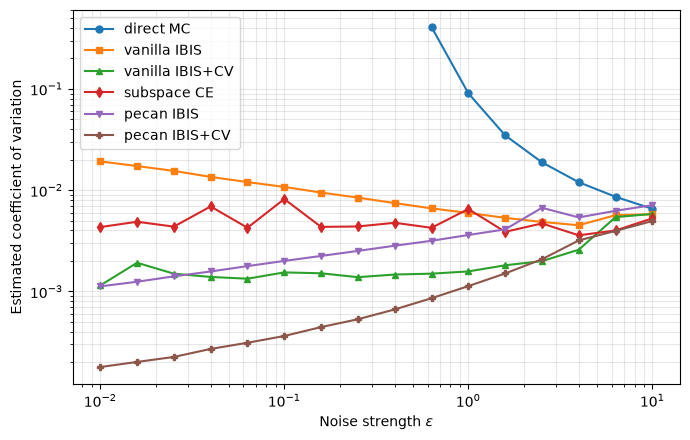

ε,direct MC,vanilla IBIS,vanilla IBIS+CV,subspace CE,pecan IBIS,pecan IBIS+CV
0.01,0.000e+00,5.044e-203,5.012e-203,4.937e-203,5.009e-203,5.012e-203
0.01585,0.000e+00,5.699e-129,5.759e-129,5.733e-129,5.758e-129,5.746e-129
0.02512,0.000e+00,3.267e-82,3.341e-82,3.329e-82,3.344e-82,3.346e-82
0.03981,0.000e+00,1.176e-52,1.166e-52,1.177e-52,1.170e-52,1.168e-52
0.0631,0.000e+00,5.660e-34,5.542e-34,5.549e-34,5.543e-34,5.552e-34
0.1,0.000e+00,3.652e-22,3.672e-22,3.647e-22,3.658e-22,3.668e-22
0.1585,0.000e+00,1.144e-14,1.144e-14,1.129e-14,1.141e-14,1.143e-14
0.2512,0.000e+00,6.569e-10,6.626e-10,6.578e-10,6.616e-10,6.625e-10
0.3981,0.000e+00,7.213e-07,7.225e-07,7.200e-07,7.229e-07,7.240e-07
0.631,6.000e-05,6.429e-05,6.448e-05,6.390e-05,6.487e-05,6.450e-05


A zero estimate for direct MC means no event hits were observed; it does not imply that the true probability is zero.


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

series = [
    ("MC",      "direct MC",       "o-"),
    ("Ibis",    "vanilla IBIS",    "s-"),
    ("CV",      "vanilla IBIS+CV", "^-"),
    ("CE",      "subspace CE",     "d-"),
    ("Pecan",   "pecan IBIS",      "v-"),
    ("PecanCV", "pecan IBIS+CV",   "P-"),
]

# CoV plot
fig, ax = plt.subplots(figsize=(7, 4.5))

eps = np.asarray(results["eps"], dtype=float)

for key, label, marker in series:
    cov = np.asarray(results["cov" + key], dtype=float)
    # Undefined or nonpositive CoVs cannot appear on logarithmic axes.
    cov = np.where(np.isfinite(cov) & (cov > 0), cov, np.nan)

    ax.loglog(eps, cov, marker, label=label, markersize=5)

ax.set_xlabel(r"Noise strength $\varepsilon$")
ax.set_ylabel("Estimated coefficient of variation")
ax.legend()
ax.grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()

# Probability table: formatting affects display only.
probabilities = pd.DataFrame({
    "ε": eps,
    **{
        label: results["prob" + key]
        for key, label, _ in series
    },
})

display(
    probabilities.style
    .hide(axis="index")
    .format({
        "ε": "{:.4g}",
        **{label: "{:.3e}" for _, label, _ in series},
    }, na_rep="—")
    .set_caption("Estimated event probabilities")
)

print(
    "A zero estimate for direct MC means no event hits were observed; "
    "it does not imply that the true probability is zero."
)